# Online-Breach Impact Estimator: multivariate regression

**Mission:** use machine learning and cybersecurity to protect individuals and organisations from online threats, promote digital safety, and give communities the knowledge they need to stay secure online.

**Use case:** When an organisation detects a cyberattack (hacking, malware or social engineering such as phishing), its incident-response team usually knows *how* the attack happened long before forensics confirms *how much* data was taken. This model takes what the team knows at detection time (attack type, attacker motive, entry vector, type of data held, industry, region, organisation size and so on) and predicts **how many records were probably exposed**.

**Who uses it and for what:** incident responders at SMEs and national CERTs. They use it to decide how urgently to warn affected people and how much to escalate the response before the real count is known. Faster, better-sized warnings protect individuals, and better triage protects organisations.

**Dataset:** [VERIS Community Database (VCDB)](https://github.com/vz-risk/VCDB) by Verizon's risk team (CC BY-SA 4.0). These are real, publicly reported security incidents coded in the [VERIS framework](https://verisframework.org). The raw data is one-hot encoded across about 2,700 columns. This notebook builds a modelling table from it and keeps only **online-threat incidents with a known number of records exposed**.

In [1]:
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

import urllib.request

RANDOM_STATE = 42
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
RAW_ZIP = DATA_DIR / "vcdb.csv.zip"
TABLE_CSV = DATA_DIR / "vcdb_online_threats.csv"
# Official source: Verizon's VCDB repository on GitHub
VCDB_URL = "https://github.com/vz-risk/VCDB/raw/master/data/csv/vcdb.csv.zip"

# Works locally (file already in the repo) and on Google Colab (downloaded on first run).
if not RAW_ZIP.exists():
    print("Downloading VCDB from", VCDB_URL)
    urllib.request.urlretrieve(VCDB_URL, RAW_ZIP)
print(f"Raw VCDB file: {RAW_ZIP} ({RAW_ZIP.stat().st_size / 1e6:.1f} MB)")

# In the repo the model goes to summative/API/; on Colab (no API folder next door) it is saved next to the notebook.
MODEL_PATH = Path("..") / "API" / "best_model.pkl" if (Path("..") / "API").is_dir() else Path("best_model.pkl")
sns.set_theme(style="whitegrid")

Raw VCDB file: data/vcdb.csv.zip (15.1 MB)


## 1. Build the modelling table from raw VCDB

In the raw VCDB CSV, every categorical value is its own True/False column, for example `action.Hacking` or `victim.employee_count.1 to 10`. For each group I take the first known value (skipping "Unknown"/"Other"), which gives one readable column per variable. Then I:

* **keep only online threats**: incidents whose action is Hacking, Malware or Social. Physical theft, lost laptops and employee error are out of scope for this mission.
* **keep only incidents with a known record count above 0**: that count is the target.
* translate the industry code (NAICS, 2 digits) and the UN region code into names a person can type into the app.

In [2]:
NAICS2 = {"11": "Agriculture", "21": "Mining", "22": "Utilities", "23": "Construction",
          "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing",
          "42": "Wholesale", "44": "Retail", "45": "Retail", "48": "Transportation", "49": "Transportation",
          "51": "Information", "52": "Finance", "53": "Real Estate", "54": "Professional Services",
          "55": "Management", "56": "Administrative", "61": "Education", "62": "Healthcare",
          "71": "Entertainment", "72": "Accommodation", "81": "Other Services", "92": "Public Administration"}
REGIONS = {"002": "Africa", "019": "Americas", "142": "Asia", "150": "Europe", "009": "Oceania"}


def build_table(raw_zip):
    with zipfile.ZipFile(raw_zip) as z:
        name = [n for n in z.namelist() if n.endswith("vcdb.csv")][0]
        cols = pd.read_csv(z.open(name), nrows=0).columns

        def group(prefix):
            return [c for c in cols if c.startswith(prefix + ".") and c.count(".") == prefix.count(".") + 1]

        groups = ["action", "actor.external.motive", "actor.external.variety", "action.hacking.vector",
                  "attribute.confidentiality.data.variety", "discovery_method", "victim.employee_count"]
        use = ["attribute.confidentiality.data_total", "timeline.incident.year", "victim.industry2", "victim.region"]
        use += [c for g in groups for c in group(g)]
        raw = pd.read_csv(z.open(name), usecols=use, dtype=str, low_memory=False)

    def flag(df):
        return df.apply(lambda s: s.str.lower().isin(["true", "1", "1.0"]))

    def first_label(prefix):
        b = flag(raw[group(prefix)])
        b.columns = [c.split(".")[-1] for c in b.columns]
        b = b[[c for c in b.columns if c.lower() not in ("unknown", "other", "na")]]
        return b.idxmax(axis=1).where(b.any(axis=1), "Unknown"), b.sum(axis=1)

    t = pd.DataFrame()
    t["incident_year"] = pd.to_numeric(raw["timeline.incident.year"], errors="coerce")
    t["action_type"], t["num_action_types"] = first_label("action")
    t["actor_motive"], _ = first_label("actor.external.motive")
    t["actor_variety"], _ = first_label("actor.external.variety")
    t["hacking_vector"], _ = first_label("action.hacking.vector")
    t["data_type"], t["num_data_types"] = first_label("attribute.confidentiality.data.variety")
    t["discovery_method"], _ = first_label("discovery_method")
    t["employee_count"], _ = first_label("victim.employee_count")
    t["industry"] = raw["victim.industry2"].str[:2].map(NAICS2).fillna("Unknown")
    t["region"] = raw["victim.region"].str[:3].map(REGIONS).fillna("Unknown")
    t["records_exposed"] = pd.to_numeric(raw["attribute.confidentiality.data_total"], errors="coerce")

    acts = flag(raw[group("action")])
    acts.columns = [c.split(".")[-1] for c in acts.columns]
    online = acts[["Hacking", "Malware", "Social"]].any(axis=1)
    print(f"All VCDB incidents: {len(t):,}")
    print(f"Online-threat incidents (Hacking/Malware/Social): {online.sum():,}")
    keep = online & (t["records_exposed"] > 0) & t["incident_year"].notna()
    t = t[keep].reset_index(drop=True)
    t["incident_year"] = t["incident_year"].astype(int)
    print(f"...with a known number of records exposed: {len(t):,}")
    return t


df = build_table(RAW_ZIP)
df.to_csv(TABLE_CSV, index=False)
df.head()

All VCDB incidents: 10,596
Online-threat incidents (Hacking/Malware/Social): 4,364
...with a known number of records exposed: 1,459


,incident_year,action_type,num_action_types,actor_motive,actor_variety,hacking_vector,data_type,num_data_types,discovery_method,employee_count,industry,region,records_exposed
0,2015,Malware,3,Financial,Unknown,Unknown,Personal,1,Internal,Small,Education,Americas,174.0
1,2024,Hacking,2,Financial,Organized crime,Unknown,Personal,1,External,1001 to 10000,Accommodation,Asia,1500000.0
2,2019,Malware,1,Financial,Organized crime,Unknown,Medical,1,External,Small,Healthcare,Americas,17214.0
3,2016,Hacking,1,Financial,Unaffiliated,Web application,Personal,1,External,10001 to 25000,Transportation,Americas,57000000.0
4,2012,Hacking,1,Grudge,Activist,Unknown,Classified,3,External,Unknown,Education,Americas,1763.0


In [3]:
print(df.shape)
df.info()

(1459, 13)
<class 'pandas.DataFrame'>
RangeIndex: 1459 entries, 0 to 1458
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   incident_year     1459 non-null   int64  
 1   action_type       1459 non-null   str    
 2   num_action_types  1459 non-null   int64  
 3   actor_motive      1459 non-null   str    
 4   actor_variety     1459 non-null   str    
 5   hacking_vector    1459 non-null   str    
 6   data_type         1459 non-null   str    
 7   num_data_types    1459 non-null   int64  
 8   discovery_method  1459 non-null   str    
 9   employee_count    1459 non-null   str    
 10  industry          1459 non-null   str    
 11  region            1459 non-null   str    
 12  records_exposed   1459 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 148.3 KB


In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
incident_year,1459.0,NaN,NaN,NaN,2015.997944,4.288866,1984.0,2013.0,2016.0,2019.0,2026.0
action_type,1459,3,Hacking,1091,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_action_types,1459.0,NaN,NaN,NaN,1.23098,0.472247,1.0,1.0,1.0,1.0,3.0
actor_motive,1459,8,Financial,658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actor_variety,1459,11,Unknown,733,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hacking_vector,1459,10,Unknown,793,NaN,NaN,NaN,NaN,NaN,NaN,NaN
data_type,1459,13,Personal,483,NaN,NaN,NaN,NaN,NaN,NaN,NaN
num_data_types,1459.0,NaN,NaN,NaN,1.331734,0.715036,0.0,1.0,1.0,2.0,6.0
discovery_method,1459,4,External,653,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employee_count,1459,11,Unknown,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Volume and variety:** the table has **1,459 incidents** and **12 feature columns**: 3 numeric (`incident_year`, `num_action_types`, `num_data_types`) and 9 categorical (`action_type`, `actor_motive`, `actor_variety`, `hacking_vector`, `data_type`, `discovery_method`, `employee_count`, `industry`, `region`). The target is `records_exposed`.

## 2. Explore the data

### 2.1 Distribution of the target

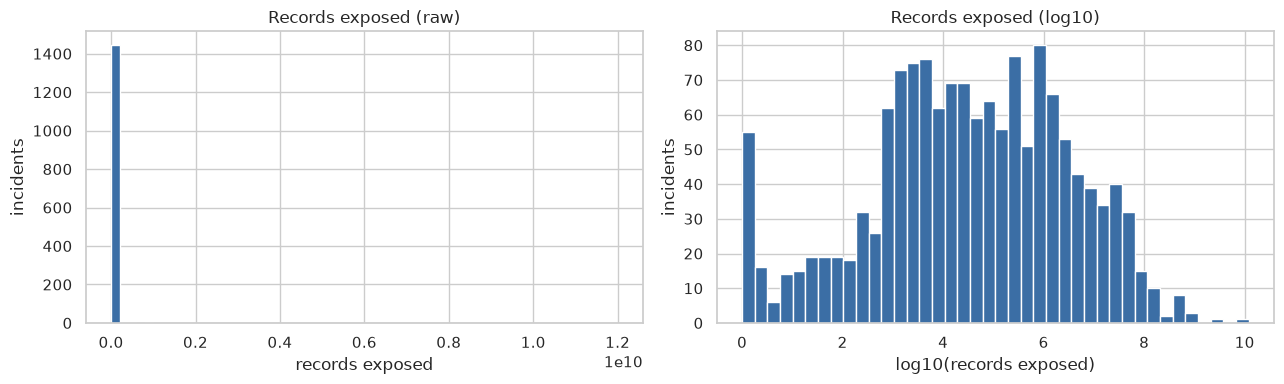

count             1,459
mean         19,793,426
std         328,241,506
min                   1
25%               1,752
50%              36,000
75%           1,000,000
max      12,000,000,000
Name: records_exposed, dtype: str


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["records_exposed"], bins=60, color="#3b6ea5")
axes[0].set(title="Records exposed (raw)", xlabel="records exposed", ylabel="incidents")
axes[1].hist(np.log10(df["records_exposed"]), bins=40, color="#3b6ea5")
axes[1].set(title="Records exposed (log10)", xlabel="log10(records exposed)", ylabel="incidents")
plt.tight_layout(); plt.show()
print(df["records_exposed"].describe().apply(lambda v: f"{v:,.0f}"))

**What it shows:** Records exposed are extremely right-skewed. The median incident exposed 36,000 records, but the mean is about 19.8 million because a handful of mega-breaches reach billions (the maximum is 12 billion). On the raw scale, MSE would be dominated by those few outliers. On a log10 scale the distribution is roughly bell-shaped, centred around 4–5 (10,000–100,000 records).

**Decision:** I model **`log_records = log10(records_exposed)`** instead of the raw count. A prediction of 4.0 means about 10,000 records, 6.0 means about 1 million. All MSE values in this notebook are in squared log10 units.

In [6]:
df["log_records"] = np.log10(df["records_exposed"])

### 2.2 Records exposed by year, and the numeric features

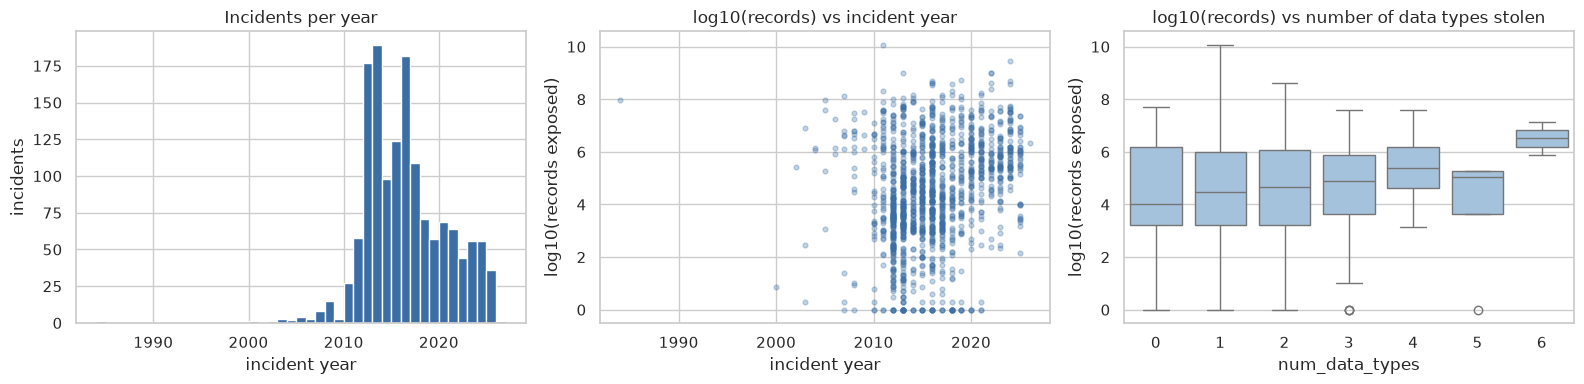

incident_year
1984    1
2000    1
2002    1
2003    3
2004    2
2005    4
Name: count, dtype: int64


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(df["incident_year"], bins=range(df["incident_year"].min(), df["incident_year"].max() + 2), color="#3b6ea5")
axes[0].set(title="Incidents per year", xlabel="incident year", ylabel="incidents")
axes[1].scatter(df["incident_year"], df["log_records"], alpha=0.3, s=12, color="#3b6ea5")
axes[1].set(title="log10(records) vs incident year", xlabel="incident year", ylabel="log10(records exposed)")
sns.boxplot(data=df, x="num_data_types", y="log_records", ax=axes[2], color="#9cc3e6")
axes[2].set(title="log10(records) vs number of data types stolen", xlabel="num_data_types", ylabel="log10(records exposed)")
plt.tight_layout(); plt.show()
print(df["incident_year"].value_counts().sort_index().loc[:2005])

**What it shows:** Almost all incidents are from 2010 onwards, with a peak in 2012–2017 when the VCDB community coded most incidents. Only 8 incidents come from before 2005 (one from 1984). The middle scatter shows breaches getting larger over time: since 2020 only 2% of incidents exposed fewer than 100 records, compared with 13% before 2020. The boxplot shows that incidents where more types of data were stolen tend to expose more records.

**Decision:** I drop the 8 incidents from before 2005. They are too few to learn a pattern from, and the 1984 incident is an outlier. That leaves **1,451 incidents**. `incident_year` and `num_data_types` stay in as numeric features.

In [8]:
MIN_YEAR = 2005
df = df[df["incident_year"] >= MIN_YEAR].reset_index(drop=True)
print("rows after removing very old incidents:", len(df))

rows after removing very old incidents: 1451


### 2.3 Records exposed by category

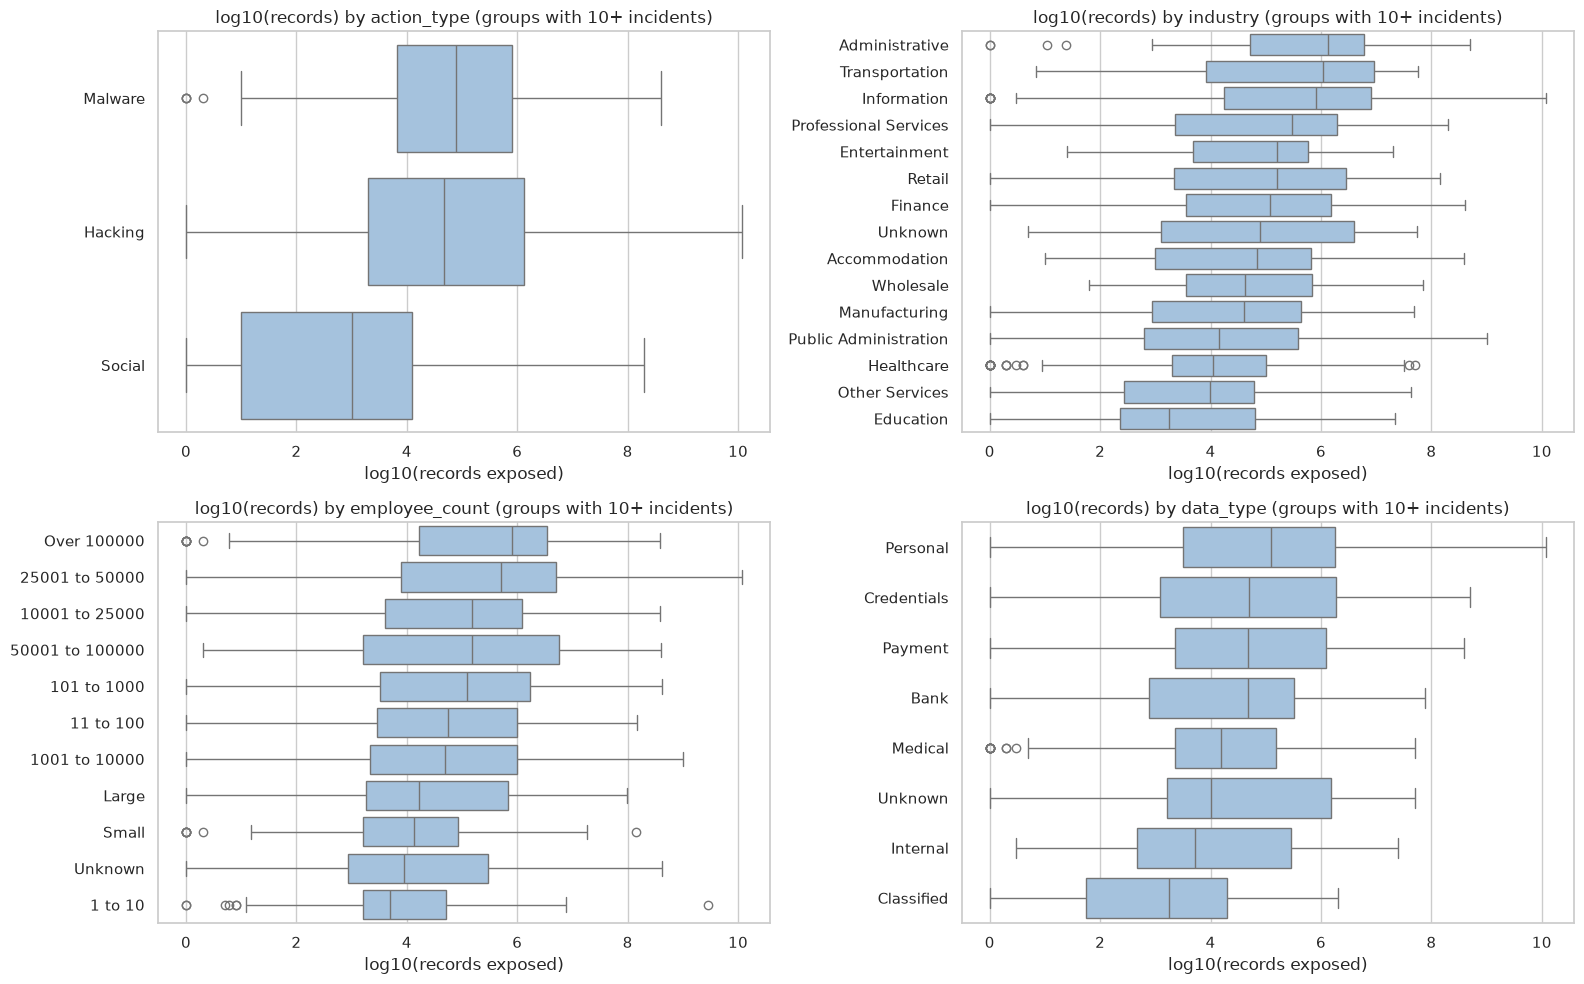

In [9]:
cats = ["action_type", "industry", "employee_count", "data_type"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, c in zip(axes.ravel(), cats):
    order = df.groupby(c)["log_records"].median().sort_values(ascending=False).index
    order = [o for o in order if (df[c] == o).sum() >= 10]
    sns.boxplot(data=df[df[c].isin(order)], y=c, x="log_records", order=order, ax=ax, color="#9cc3e6")
    ax.set(title=f"log10(records) by {c} (groups with 10+ incidents)", xlabel="log10(records exposed)", ylabel="")
plt.tight_layout(); plt.show()

**What it shows:** Social-engineering attacks such as phishing expose far fewer records (median about 1,000) than hacking or malware (median about 50,000–80,000), because phishing usually compromises a few mailboxes rather than a whole database. Administrative-services, transportation and information-sector victims (online platforms, telecoms) have the largest breaches, while education and healthcare have the smallest. Larger organisations tend to lose more records, but the boxes overlap a lot. Incidents involving personal data are larger than those involving internal or classified documents.

**Decision:** these categorical columns carry signal, so I keep them and one-hot encode them. Rare categories (fewer than 10 incidents) are grouped into one "infrequent" column so the models don't fit noise.

### 2.4 Correlation heatmap

To get correlations for categorical features, I one-hot encode them first and keep the 15 columns most correlated with the target.

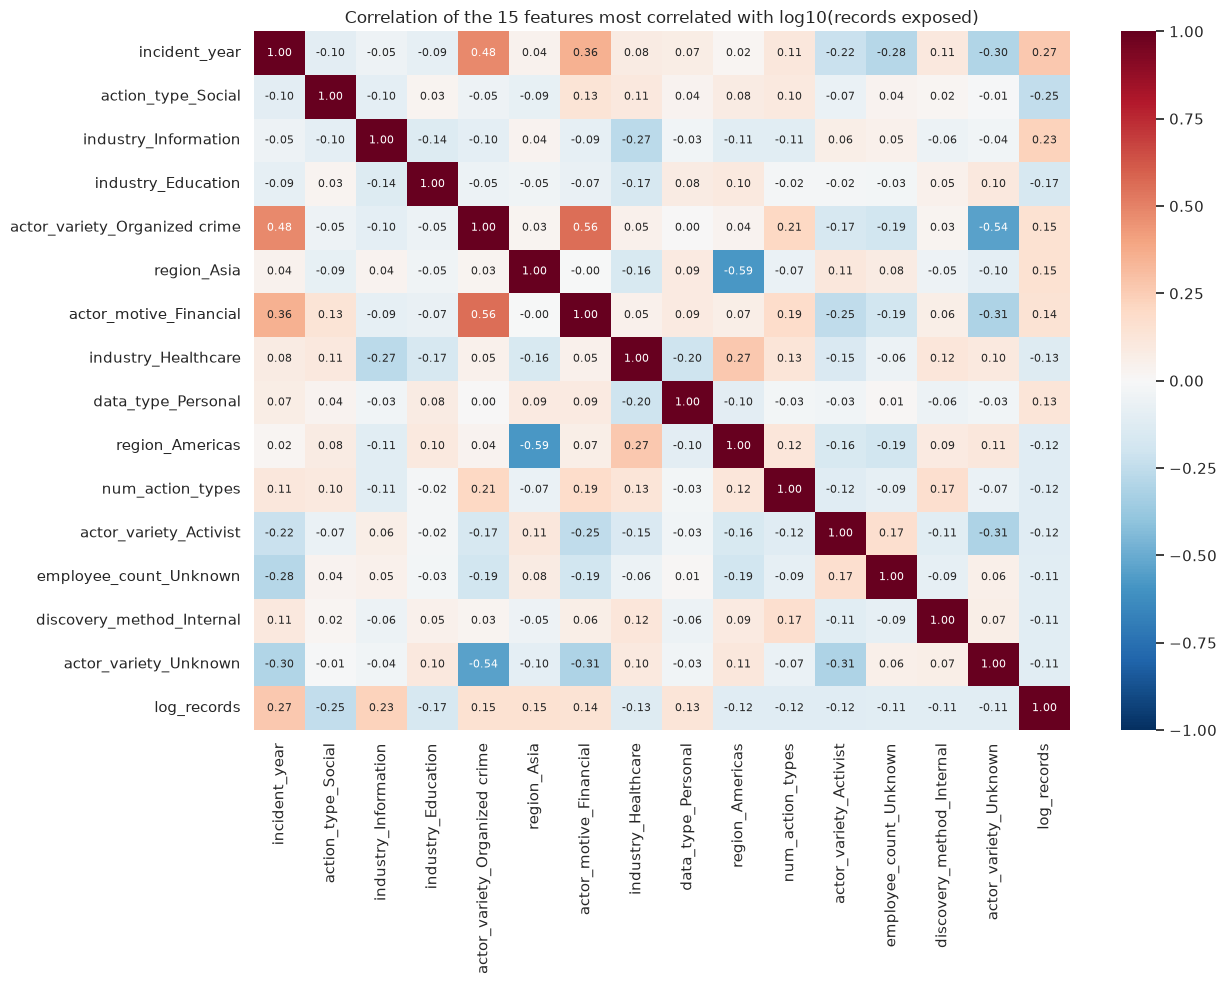

incident_year                    0.273
action_type_Social              -0.248
industry_Information             0.230
industry_Education              -0.168
actor_variety_Organized crime    0.155
region_Asia                      0.150
actor_motive_Financial           0.141
industry_Healthcare             -0.131
data_type_Personal               0.129
region_Americas                 -0.121
num_action_types                -0.121
actor_variety_Activist          -0.120
employee_count_Unknown          -0.113
discovery_method_Internal       -0.112
actor_variety_Unknown           -0.110
Name: log_records, dtype: float64

In [10]:
NUMERIC = ["incident_year", "num_action_types", "num_data_types"]
CATEGORICAL = ["action_type", "actor_motive", "actor_variety", "hacking_vector", "data_type",
               "discovery_method", "employee_count", "industry", "region"]
FEATURES = NUMERIC + CATEGORICAL
TARGET = "log_records"

encoded = pd.get_dummies(df[FEATURES], columns=CATEGORICAL, dtype=float)
encoded[TARGET] = df[TARGET]
corr_with_target = encoded.corr()[TARGET].drop(TARGET)
top = corr_with_target.abs().sort_values(ascending=False).head(15).index.tolist()
plt.figure(figsize=(13, 10))
sns.heatmap(encoded[top + [TARGET]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 8})
plt.title("Correlation of the 15 features most correlated with log10(records exposed)")
plt.tight_layout(); plt.show()
corr_with_target.loc[top].round(3)

**What it shows:** The strongest single correlation with `log_records` is `incident_year` (+0.27), followed by `action_type_Social` (−0.25) and `industry_Information` (+0.23). Every other feature is under |0.17|. Among the features themselves, the strongest links are organised-crime actors with financial motives (+0.56) and with more recent years (+0.48), and Asia vs Americas (−0.59, because each incident has one region). None of these are high enough to cause serious multicollinearity.

**Decision:** no single feature explains much on its own, and the categorical features don't strongly duplicate each other. So I keep all 12 features and let the models combine them. The weak linear correlations also suggest that tree models, which can capture interactions such as "industry × year", may do better than linear ones.

## 3. Feature engineering

**Columns I dropped from the raw VCDB data, and why:**
* **Malware vector and social-engineering vector:** "Unknown" for 93% and 87% of incidents, so they would add almost nothing.
* **Asset type and actor type:** 85% "Server" and 97% "External" respectively, so they barely vary.
* **Victim country:** over 60 values, most with only a handful of incidents. `region` keeps the geography with enough data per group.
* **Timeline columns (time to discovery or containment):** only known after the investigation ends. The model is meant for the moment of detection, so using them would be leakage.
* **Free-text notes, IDs, references and source fields:** not predictive, and unique per incident.
* **`records_exposed`:** replaced by its log, `log_records`, as the target.

**Features that matter most:** according to both the correlations and the random-forest importances in section 7.1, the strongest signals are **incident year** (breaches are getting bigger), **whether the attack was social engineering** (smaller), **whether the victim is in the information sector** (larger), **the number of action and data types involved**, **the data type** (credentials and personal data) and **how the breach was discovered**.

**Converting categorical to numeric:** `OneHotEncoder(handle_unknown="ignore", min_frequency=10)` inside a `ColumnTransformer`. Numeric columns go through `StandardScaler`.

## 4. Train/test split and standardisation

In [11]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False), CATEGORICAL),
    ])

# The scaler and encoder are fitted on the TRAINING set only, then applied to the test set.
preprocessor = make_preprocessor().fit(X_train)
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)
print("train:", X_train_t.shape, " test:", X_test_t.shape)
print("scaled numeric columns in train -> mean", X_train_t[:, :3].mean(0).round(3), "std", X_train_t[:, :3].std(0).round(3))

train: (1160, 69)  test: (291, 69)
scaled numeric columns in train -> mean [ 0.  0. -0.] std [1. 1. 1.]


## 5. Model 1: linear regression by gradient descent (`SGDRegressor`)

### 5.1 Hyperparameter tuning

I tune the **learning rate** (`eta0`), the **L2 regularisation strength** (`alpha`) and the **number of epochs**. To keep the test set untouched, tuning uses a validation split carved out of the training set. Each configuration is trained with `partial_fit`, one pass over the shuffled data per epoch.

In [12]:
def train_sgd(Xa, ya, Xb, yb, eta0, alpha, epochs, seed=RANDOM_STATE):
    # Train an SGDRegressor epoch by epoch; return the model and per-epoch MSE on (Xa, ya) and (Xb, yb).
    model = SGDRegressor(learning_rate="constant", eta0=eta0, alpha=alpha, penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    ya, yb = np.asarray(ya), np.asarray(yb)
    hist_a, hist_b = [], []
    for _ in range(epochs):
        idx = rng.permutation(len(ya))
        model.partial_fit(Xa[idx], ya[idx])
        hist_a.append(mean_squared_error(ya, model.predict(Xa)))
        hist_b.append(mean_squared_error(yb, model.predict(Xb)))
    return model, hist_a, hist_b


X_tr_sub, X_val, y_tr_sub, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)
tune_pre = make_preprocessor().fit(X_tr_sub)
Xs, Xv = tune_pre.transform(X_tr_sub), tune_pre.transform(X_val)

rows = []
for eta0 in [0.0001, 0.001, 0.01, 0.05]:
    for alpha in [0.0001, 0.001, 0.01, 0.1]:
        _, ha, hb = train_sgd(Xs, y_tr_sub, Xv, y_val, eta0, alpha, epochs=200)
        for ep in [25, 50, 100, 200]:
            rows.append({"eta0": eta0, "alpha": alpha, "epochs": ep, "train_mse": ha[ep - 1], "val_mse": hb[ep - 1]})
tuning = pd.DataFrame(rows).sort_values("val_mse")
tuning.head(10).round(4)

,eta0,alpha,epochs,train_mse,val_mse
26,0.0010,0.0100,100,2.6709,2.7700
24,0.0010,0.0100,25,2.7295,2.7721
11,0.0001,0.0100,200,2.7497,2.7776
20,0.0010,0.0010,25,2.7151,2.7796
16,0.0010,0.0001,25,2.7138,2.7807
7,0.0001,0.0010,200,2.7363,2.7816
3,0.0001,0.0001,200,2.7350,2.7822
25,0.0010,0.0100,50,2.6897,2.7830
27,0.0010,0.0100,200,2.6705,2.7886
22,0.0010,0.0010,100,2.6505,2.8006


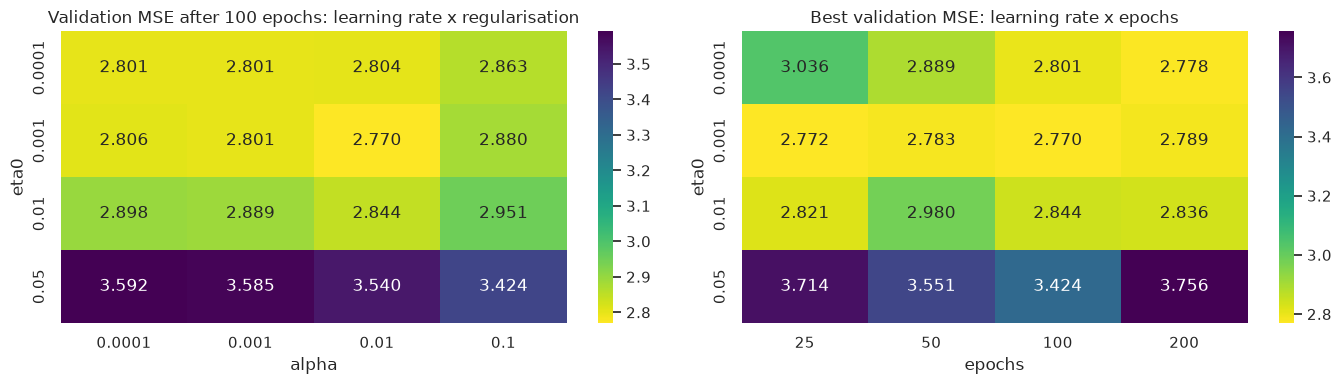

Chosen: eta0=0.001, alpha=0.01, epochs=100 (validation MSE 2.7700)


In [13]:
pivot_lr = tuning[tuning.epochs == 100].pivot(index="eta0", columns="alpha", values="val_mse")
pivot_ep = tuning.groupby(["eta0", "epochs"])["val_mse"].min().unstack()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(pivot_lr, annot=True, fmt=".3f", cmap="viridis_r", ax=axes[0])
axes[0].set_title("Validation MSE after 100 epochs: learning rate x regularisation")
sns.heatmap(pivot_ep, annot=True, fmt=".3f", cmap="viridis_r", ax=axes[1])
axes[1].set_title("Best validation MSE: learning rate x epochs")
plt.tight_layout(); plt.show()

best = tuning.iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = float(best.eta0), float(best.alpha), int(best.epochs)
print(f"Chosen: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS} (validation MSE {best.val_mse:.4f})")

**What tuning showed:** **Learning rate (`eta0`)** had the biggest effect. At 0.05 the updates overshoot and validation MSE stays above 3.4, close to the 3.75 you'd get by always predicting the mean. 0.001 is the sweet spot. 0.0001 also works but needs about 200 epochs to get there. **Regularisation (`alpha`)** had a smaller effect: a moderate value of 0.01 gave the best validation MSE, while 0.1 shrank the weights too much and raised the error. **Epochs:** with `eta0=0.001`, validation MSE stops improving after about 25–100 epochs, and going to 200 makes it slightly worse. The chosen combination is **eta0 = 0.001, alpha = 0.01, 100 epochs**.

### 5.2 Loss curve: train and test MSE per epoch

I retrain on the full training set with the chosen settings. After every epoch I record train MSE and test MSE (scikit-learn doesn't record these itself).

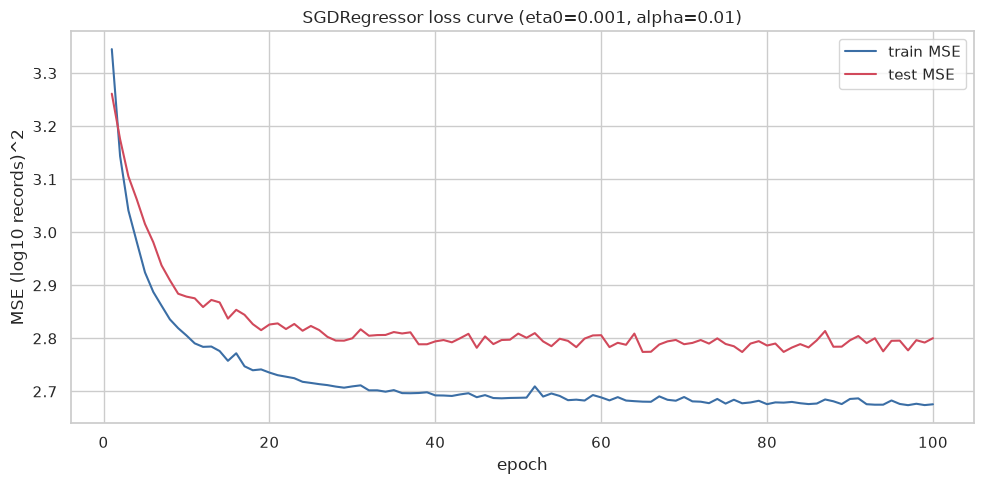

final train MSE 2.6758   final test MSE 2.8004


In [14]:
sgd, train_curve, test_curve = train_sgd(X_train_t, y_train, X_test_t, y_test, BEST_ETA0, BEST_ALPHA, BEST_EPOCHS)
plt.figure(figsize=(10, 5))
plt.plot(range(1, BEST_EPOCHS + 1), train_curve, label="train MSE", color="#3b6ea5")
plt.plot(range(1, BEST_EPOCHS + 1), test_curve, label="test MSE", color="#d1495b")
plt.xlabel("epoch"); plt.ylabel("MSE (log10 records)^2")
plt.title(f"SGDRegressor loss curve (eta0={BEST_ETA0}, alpha={BEST_ALPHA})")
plt.legend(); plt.tight_layout(); plt.show()
print(f"final train MSE {train_curve[-1]:.4f}   final test MSE {test_curve[-1]:.4f}")

**What it shows:** Both losses fall quickly over the first 20 epochs and then flatten out. Train MSE settles at about 2.68 and test MSE at about 2.80. Test MSE doesn't rise again later, so the model isn't overfitting, and the small gap between the curves is the normal train/test difference. The small wiggles come from stochastic gradient descent updating on one shuffled sample at a time. The flat ending shows a linear model has reached its limit on this data, so more epochs won't help.

## 6. Models 2–4: closed-form linear regression, decision tree, random forest

In [15]:
lin = LinearRegression().fit(X_train_t, y_train)

# Decision tree: limit depth and leaf size, otherwise it memorises the training set.
tree_scores = {}
for depth in [3, 4, 5, 6, 8, 10, None]:
    for leaf in [5, 10, 20]:
        m = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=RANDOM_STATE)
        m.fit(preprocessor.transform(X_tr_sub), y_tr_sub)  # tuned on the validation split, not the test set
        tree_scores[(depth, leaf)] = mean_squared_error(y_val, m.predict(preprocessor.transform(X_val)))
(best_depth, best_leaf) = min(tree_scores, key=tree_scores.get)
tree = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf, random_state=RANDOM_STATE).fit(X_train_t, y_train)
print(f"Decision tree: max_depth={best_depth}, min_samples_leaf={best_leaf}")

forest_scores = {}
for leaf in [3, 5, 10]:  # leaf=1 memorises the training set and makes a 30 MB model file
    for feats in [0.3, 0.5, 1.0]:
        m = RandomForestRegressor(n_estimators=200, min_samples_leaf=leaf, max_features=feats,
                                  random_state=RANDOM_STATE, n_jobs=-1)
        m.fit(preprocessor.transform(X_tr_sub), y_tr_sub)
        forest_scores[(leaf, feats)] = mean_squared_error(y_val, m.predict(preprocessor.transform(X_val)))
(best_rf_leaf, best_rf_feats) = min(forest_scores, key=forest_scores.get)
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=best_rf_leaf, max_features=best_rf_feats,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_t, y_train)
print(f"Random forest: min_samples_leaf={best_rf_leaf}, max_features={best_rf_feats}")

Decision tree: max_depth=5, min_samples_leaf=10


Random forest: min_samples_leaf=3, max_features=0.3


## 7. Comparison of all four models on the same test set

In [16]:
models = {"SGDRegressor (gradient descent)": sgd, "LinearRegression (closed form)": lin,
          "DecisionTreeRegressor": tree, "RandomForestRegressor": forest}
results = pd.DataFrame([
    {"model": name,
     "train_MSE": mean_squared_error(y_train, m.predict(X_train_t)),
     "test_MSE": mean_squared_error(y_test, m.predict(X_test_t))}
    for name, m in models.items()
]).set_index("model").sort_values("test_MSE")
baseline = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"Baseline (always predict the training mean): test MSE = {baseline:.4f}")
results.round(4)

Baseline (always predict the training mean): test MSE = 3.7532


,train_MSE,test_MSE
model,,
RandomForestRegressor,1.4341,2.6023
SGDRegressor (gradient descent),2.6758,2.8004
LinearRegression (closed form),2.6459,2.8004
DecisionTreeRegressor,2.7169,2.9160


In [17]:
best_name = results["test_MSE"].idxmin()
best_model = models[best_name]
print(f"Best model (lowest test MSE): {best_name}  ->  test MSE {results.loc[best_name, 'test_MSE']:.4f}")

Best model (lowest test MSE): RandomForestRegressor  ->  test MSE 2.6023


**Best model and why:** the **Random Forest** has the lowest test MSE (**2.60**, compared with 2.80 for both linear models, 2.92 for the decision tree, and 3.75 for always predicting the mean). It is saved as the best model. It suits this problem because the size of a breach depends on *combinations* of factors: for example, hacking an information-sector company is very different from phishing a small school. The forest captures these interactions automatically, while a linear model can only add up one effect per feature. Averaging 200 trees also smooths out the noise that hurts a single tree.

**How the dataset affected each model:** **Linear models (SGD and closed form):** the strongest correlation is only 0.27 and most features are one-hot columns, so a straight-line combination misses the interactions. Both implementations converge to the same test MSE (2.80), which confirms gradient descent found the same solution as the exact formula. **Decision tree:** with only 1,160 training rows and 69 encoded columns, a single deep tree memorises noise. Validation picked a shallow tree (depth 5, at least 10 samples per leaf), which is too simple to beat the linear models, so it has the worst MSE (2.92). **Random forest:** its train MSE (1.43) is much lower than its test MSE (2.60), so it does overfit somewhat. But averaging many de-correlated trees still gives the best result on unseen incidents. The dataset itself limits all four models: many fields are "Unknown" (half of actor varieties and hacking vectors), and record counts come from public reports that are often rough estimates. So some error can't be removed.

### 7.1 Feature importance (random forest)

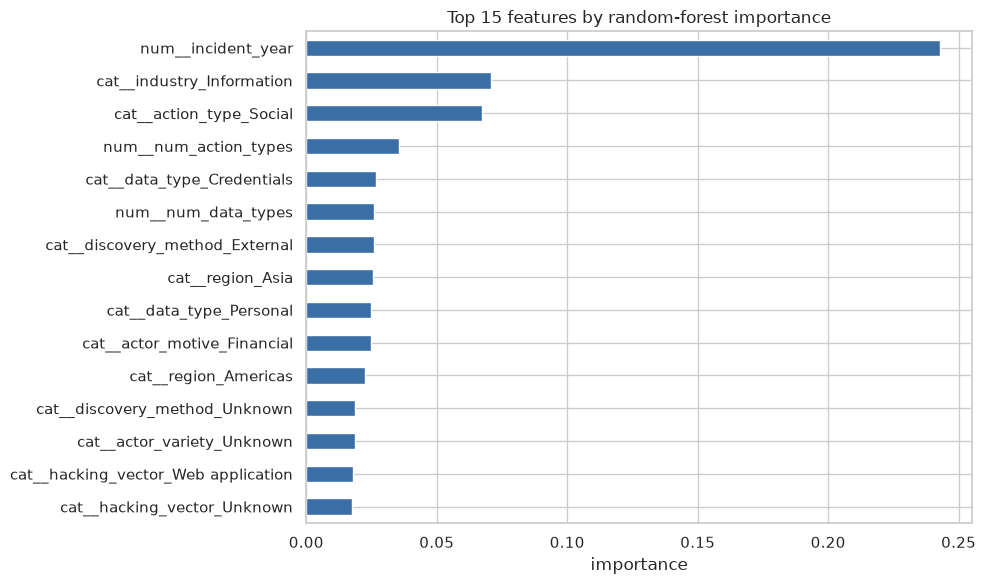

In [18]:
names = preprocessor.get_feature_names_out()
imp = pd.Series(forest.feature_importances_, index=names).sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
imp[::-1].plot.barh(color="#3b6ea5")
plt.title("Top 15 features by random-forest importance"); plt.xlabel("importance")
plt.tight_layout(); plt.show()

## 8. Scatter plots: most-correlated feature vs target, before and after fitting a line

The feature most correlated with the target (from the correlation step above) is plotted against `log_records`. For the "after" plot, I fit a **one-feature linear regression** on the training set, used only for this plot.

Feature most correlated with the target: incident_year (r = 0.273)


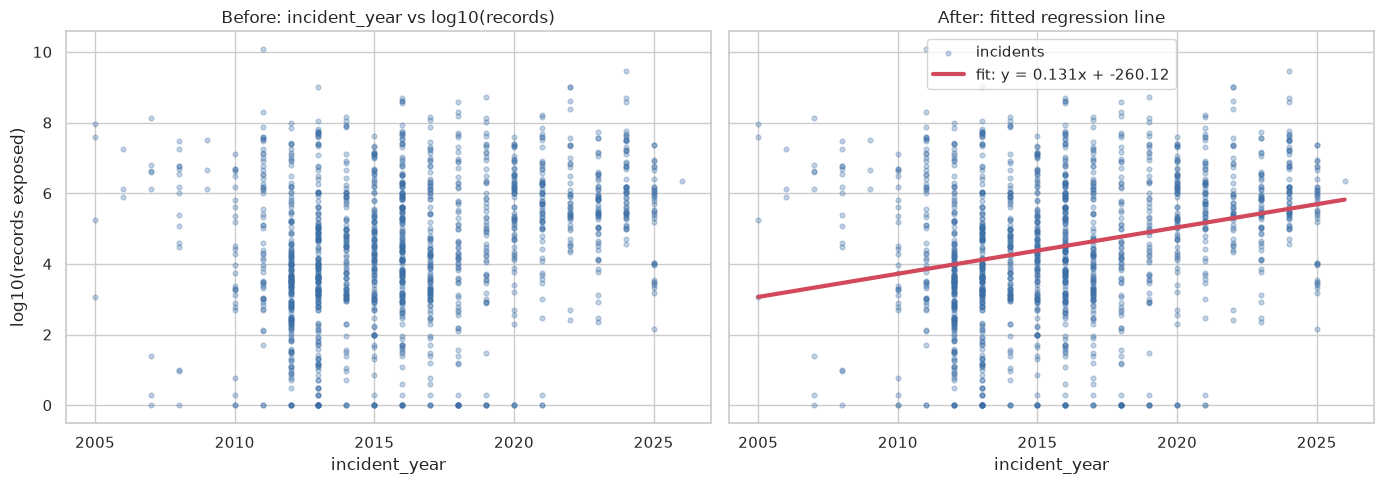

In [19]:
top_feature = corr_with_target.abs().idxmax()
print("Feature most correlated with the target:", top_feature, f"(r = {corr_with_target[top_feature]:.3f})")
x_all = encoded[top_feature].loc[df.index]
jitter = np.random.default_rng(0).uniform(-0.25, 0.25, len(x_all)) if x_all.nunique() <= 2 else 0

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].scatter(x_all + jitter, df[TARGET], alpha=0.3, s=12, color="#3b6ea5")
axes[0].set(title=f"Before: {top_feature} vs log10(records)", xlabel=top_feature, ylabel="log10(records exposed)")

one = LinearRegression().fit(x_all.loc[X_train.index].to_frame(), y_train)
grid = np.linspace(x_all.min(), x_all.max(), 100)
axes[1].scatter(x_all + jitter, df[TARGET], alpha=0.3, s=12, color="#3b6ea5", label="incidents")
axes[1].plot(grid, one.predict(pd.DataFrame({top_feature: grid})), color="#d1495b", lw=3,
             label=f"fit: y = {one.coef_[0]:.3f}x + {one.intercept_:.2f}")
axes[1].set(title=f"After: fitted regression line", xlabel=top_feature)
axes[1].legend(); plt.tight_layout(); plt.show()

**What it shows:** Each dot is one incident. The fitted line has a positive slope of about 0.13 log10-units per year, so a typical breach is about 35% larger each year, or about 20 times larger per decade. The points are widely scattered around the line: year alone explains only about 7% of the variance (r = 0.27). That's why the full models combine all 12 features.

## 9. Save the best model with its preprocessing

The saved object is a single scikit-learn `Pipeline` (scaler + one-hot encoder + model), so the API can pass it raw values exactly as a user types them.

In [20]:
final_pipeline = Pipeline([("preprocess", preprocessor), ("model", best_model)])
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_pipeline, MODEL_PATH, compress=3)
print("Saved", best_name, "pipeline to", MODEL_PATH.resolve())
# sanity check: the pipeline reproduces the test MSE from the table
print("pipeline test MSE:", round(mean_squared_error(y_test, final_pipeline.predict(X_test)), 4))

Saved RandomForestRegressor pipeline to /home/claude/linear_regression_model/summative/API/best_model.pkl
pipeline test MSE: 2.6023


## 10. Predict with the saved model on one row of the test set

`predict_records_exposed` loads the saved pipeline and predicts for one row. Task 2 (the API) reuses this same function.

In [21]:
def predict_records_exposed(row: dict, model_path=MODEL_PATH) -> dict:
    # Load the saved pipeline and predict records exposed for one incident.
    pipeline = joblib.load(model_path)
    log_pred = float(pipeline.predict(pd.DataFrame([row])[FEATURES])[0])
    return {"predicted_log10_records": round(log_pred, 3),
            "predicted_records_exposed": int(round(10 ** log_pred))}


one_row = X_test.iloc[0].to_dict()
print("Input row:", one_row)
print("Prediction:", predict_records_exposed(one_row))
print("Actual records exposed:", f"{int(round(10 ** y_test.iloc[0])):,}", f"(log10 = {y_test.iloc[0]:.3f})")

Input row: {'incident_year': 2015, 'num_action_types': 1, 'num_data_types': 1, 'action_type': 'Hacking', 'actor_motive': 'Financial', 'actor_variety': 'Unknown', 'hacking_vector': 'Unknown', 'data_type': 'Credentials', 'discovery_method': 'External', 'employee_count': '101 to 1000', 'industry': 'Information', 'region': 'Americas'}
Prediction: {'predicted_log10_records': 5.622, 'predicted_records_exposed': 418571}
Actual records exposed: 50,000 (log10 = 4.699)


## 11. Summary

| | |
|---|---|
| Rows / features | 1,451 incidents, 12 features (3 numeric, 9 categorical) |
| Target | log10(records exposed) |
| Best model | **Random Forest**: test MSE **2.60** (baseline 3.75) |
| Saved to | `../API/best_model.pkl` (preprocessing + model in one Pipeline) |

**Is the test loss high or low?** A test MSE of 2.60 in log10 units means an RMSE of about 1.6, so a typical prediction is within a factor of about 40 of the true count. That is high in absolute terms, but it is 31% lower than the baseline. For triage, the useful output is the *order of magnitude* (hundreds vs millions of records), and the model separates those reasonably well. **To reduce it further:** collect more incidents with known record counts (only about a third of VCDB online-threat incidents have one), reduce the "Unknown" values, add features such as whether the stolen data was encrypted or whether it was a ransomware attack, and try gradient-boosted trees.